In [1]:
#
# Reference Link: https://stackoverflow.com/questions/59581706/perceptron-algorithm-plotting-with-matplotlib
#
import numpy as np
import pandas as pd
import random
from google.colab import drive
import os

google_drive_path = '/content/drive/MyDrive/Colab_Notebooks/Data/perceptron_data.csv' # Replace with your path

# Code to find the current working directory in google drive.
drive.mount('/content/drive')
current_working_directory = os.getcwd()
print(current_working_directory)

# Setting the random seed, feel free to change it and see different solutions.
np.random.seed(42)
import matplotlib.pyplot as plt


def stepFunction(t):
    return 1 if t >= 0 else 0


def prediction(X, W, b):
    return stepFunction((np.matmul(X, W) + b)[0])

# TODO: Fill in the code below to implement the perceptron trick.
# INPUTS
# data X, the labels y,
# the weights W (as an array), and the bias b,
# The function  weights and bias W, b, according to the perceptron algorithm,
# and return W and b.

def perceptronStep(X, y, W, b, learn_rate=0.01):
    for i in range(len(X)):
        y_hat = prediction(X[i], W, b)
        if y[i] - y_hat == 1:
            W[0] += X[i][0] * learn_rate
            W[1] += X[i][1] * learn_rate
            b += learn_rate
        elif y[i] - y_hat == -1:
            W[0] -= X[i][0] * learn_rate
            W[1] -= X[i][1] * learn_rate
            b -= learn_rate
    return W, b

# This function runs the perceptron algorithm repeatedly on the dataset,
# and returns a few of the boundary lines obtained in the iterations,
# for plotting purposes.
# Feel free to play with the learning rate and the num_epochs,
# and see your results plotted below.
def trainPerceptronAlgorithm(X, y, learn_rate=0.01, num_epochs=25):
    x_min, x_max = min(X.T[0]), max(X.T[0])
    y_min, y_max = min(X.T[1]), max(X.T[1])
    W = np.array(np.random.rand(2, 1))
    b = np.random.rand(1)[0] + x_max
    # These are the solution lines that get plotted below.
    boundary_lines = []
    for i in range(num_epochs):
        # In each epoch, we apply the perceptron step.
        W, b = perceptronStep(X, y, W, b, learn_rate)
        # Here I have a doubt . Why if y = W0*x1 + W1*x2 + b
        # So we can get  x2 =y/W1 -(W0*x1)/W1 -b/W1 + y/W1)
        # If we remove y/W1 we just get intercept and slope
        # But why we are not using the last term y/W1
        boundary_lines.append((-W[0] / W[1], -b / W[1]))
    return boundary_lines

Mounted at /content/drive
/content


In [2]:
# Generate random data
def generate_data(no_points):
    X = np.zeros(shape=(no_points, 2))
    Y = np.zeros(shape=no_points)
    for ii in range(no_points):
        X[ii][0] = random.randint(1,9)+0.5
        X[ii][1] = random.randint(1,9)+0.5
        Y[ii] = 1 if X[ii][0]+X[ii][1] >= 13 else -1
    return X, Y

In [3]:

# Get data and plot the points from file
# data = pd.read_csv('perceptron_data.csv', header = None)
perceptron_data = pd.read_csv(google_drive_path, header = None)

X = perceptron_data.iloc[:, :2].values
y = perceptron_data.iloc[:, -1].values

#In the 2D case, the perceptron algorithm looks like:
#X, y = generate_data(100)

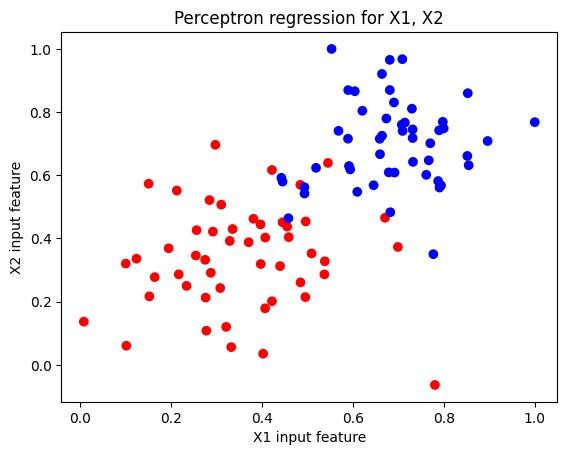

In [4]:
x1 = X[:, 0]
x2 = X[:, 1]
color = ['red' if value == 1 else 'blue' for value in y]
plt.scatter(x1, x2, marker='o', color=color)
plt.xlabel('X1 input feature')
plt.ylabel('X2 input feature')
plt.title('Perceptron regression for X1, X2')
plt.show()

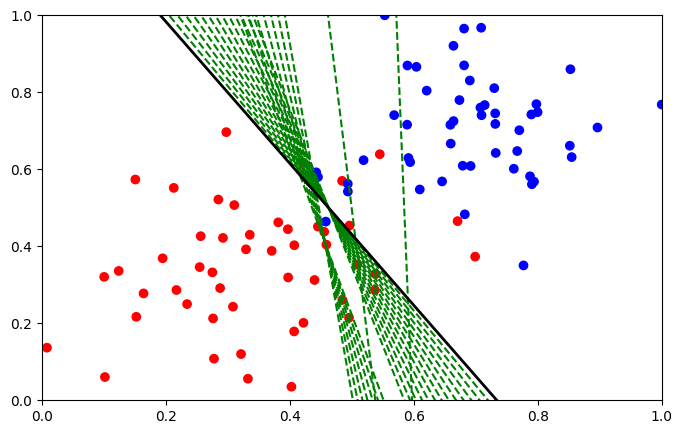

In [5]:
# So now lets plot the lines that represent the best function for each iteration
boundary_lines = trainPerceptronAlgorithm(X, y)
x_lin = np.linspace(0, 1, 100)

fig, ax = plt.subplots(1, 1, figsize=(8,5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.scatter(x1, x2, marker='o', color=color)
for i, line in enumerate(boundary_lines):
    Θo, Θ1  = line
    if i == len(boundary_lines) - 1:
        c, ls, lw = 'k', '-', 2
    else:
        c, ls, lw = 'g', '--', 1.5
    ax.plot(x_lin, Θo * x_lin + Θ1, c=c, ls=ls, lw=lw)
plt.show()